# CUAD contract review — analysis pipeline

Consolidated working notebook. Each section corresponds to a GitHub issue; the per-issue
notebooks are kept alongside this one as the source of truth while this file is assembled.

| Section | Issue |
| --- | --- |
| 1. Load CUAD dataset | #6 |
| 2. Clean the data | #7 |
| 3. EDA: class imbalance | #9 |
| 4. Category selection | #14 |
| 5. Chunking strategy | #11 |

Run top to bottom: each section depends on the frames built by the ones above it.

## 0. Setup

All imports, paths and plot settings for every section below.

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from transformers import AutoTokenizer

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 130, "axes.titlesize": 11, "axes.labelsize": 10})

DATA_DIR = Path("../data/cuad")
OUT_DIR = Path("../data/processed")
TRAIN_PATH = DATA_DIR / "train_separate_questions.json"
TEST_PATH = DATA_DIR / "test.json"

---

# 1. Load CUAD dataset

Loads the official CUAD train/test JSON files and flattens them into a clause-level DataFrame
(one row per annotated span) with: contract ID, category, clause text, and span offsets.

Data files are in `data/cuad/` (see `data/cuad/README.md`). We use the official
`train_separate_questions.json` (408 contracts) and `test.json` (102 contracts) splits as-is.

## 1.1 Flatten the JSON

Each file is SQuAD-style: `data[] -> paragraphs[] -> qas[] -> answers[]`. Every contract has one paragraph
whose `context` is the full contract text, and one question per category.

Note: in `train_separate_questions.json` each answer span is split out into its own question, so the
question ids end in `_0`, `_1`, ... (e.g. `...__Parties_3`). We strip that suffix to recover the category name.
`test.json` has one question per category with multiple answers instead.

In [2]:
def category_from_id(qid: str) -> str:
    """'<contract title>__Parties_3' -> 'Parties'"""
    return re.sub(r"_\d+$", "", qid.split("__")[-1])


def load_cuad(path):
    """Return (clauses_df, contracts_df).

    clauses_df:   one row per annotated span
    contracts_df: one row per contract with the full text
    """
    with open(path) as f:
        data = json.load(f)["data"]

    clause_rows, contract_rows = [], []
    for contract in data:
        contract_id = contract["title"]
        for para in contract["paragraphs"]:
            contract_rows.append({"contract_id": contract_id, "text": para["context"]})
            for qa in para["qas"]:
                category = category_from_id(qa["id"])
                for ans in qa["answers"]:
                    start = ans["answer_start"]
                    clause_rows.append({
                        "contract_id": contract_id,
                        "category": category,
                        "clause_text": ans["text"],
                        "start": start,
                        "end": start + len(ans["text"]),
                    })

    return pd.DataFrame(clause_rows), pd.DataFrame(contract_rows)

In [3]:
train_clauses, train_contracts = load_cuad(TRAIN_PATH)
test_clauses, test_contracts = load_cuad(TEST_PATH)

print(f"train: {len(train_contracts)} contracts, {len(train_clauses)} clause spans")
print(f"test:  {len(test_contracts)} contracts, {len(test_clauses)} clause spans")

train: 408 contracts, 11180 clause spans
test:  102 contracts, 2643 clause spans


In [4]:
train_clauses.head(10)

,contract_id,category,clause_text,start,end
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Document Name,DISTRIBUTOR AGREEMENT,44,65
1,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,Distributor,244,255
2,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,Electric City of Illinois L.L.C.,49574,49606
3,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,Electric City of Illinois LLC,212,241
4,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,Company,197,204
5,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,Electric City Corp.,148,167
6,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Agreement Date,"7th day of September, 1999.",263,290
7,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Effective Date,Unless earlier terminated otherwise prov...,31058,31270
8,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Effective Date,The term of this Agreement shall be ten (10)...,5268,5541
9,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Expiration Date,The term of this Agreement shall be ten (10)...,5268,5541


In [5]:
train_contracts.head()

,contract_id,text
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,EXHIBIT 10.6\n\n ...
1,"WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION A...",Exhibit 10.26 CONFIDENTIAL TREATMENT HAS BE...
2,NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT,Exhibit 1\n\nJOINT FILING AGREEMENT\n\nThe und...
3,ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT A...,REDACTED COPY\n\nCONFIDENTIAL TREATMENT REQUES...
4,"KIROMICBIOPHARMA,INC_05_11_2020-EX-10.23-CONSU...",Exhibit 10.23 Corporate Address Fannin South P...


## 1.2 Sanity checks

- 41 categories in train. Test only has 40: `Price Restrictions` has no positive spans in any test contract
  (it is a rare category, ~4% of train contracts).
- Span offsets point at the clause text in the contract

In [6]:
train_cats = set(train_clauses["category"])
test_cats = set(test_clauses["category"])
print("train categories:", len(train_cats))
print("test categories: ", len(test_cats))
print("in train but not test:", train_cats - test_cats)
assert len(train_cats) == 41 and test_cats <= train_cats

train categories: 41
test categories:  40
in train but not test: {'Price Restrictions'}


In [7]:
def check_offsets(clauses, contracts):
    text_by_id = contracts.set_index("contract_id")["text"]
    sliced = [
        text_by_id[row.contract_id][row.start:row.end]
        for row in clauses.itertuples()
    ]
    return (pd.Series(sliced) == clauses["clause_text"].values).mean()

print("train offset match rate:", check_offsets(train_clauses, train_contracts))
print("test offset match rate: ", check_offsets(test_clauses, test_contracts))

train offset match rate: 1.0
test offset match rate:  1.0


## 1.3 Contract-level label matrix

A multi-hot `contracts x 41 categories` matrix (1 if the contract has at least one span for that category).
Useful for the contract-level split (#8) and the EDA on class imbalance (#9).

In [8]:
def label_matrix(clauses, contracts):
    mat = pd.crosstab(clauses["contract_id"], clauses["category"]).clip(upper=1)
    # keep every contract, even ones with no spans, and a fixed column order
    return mat.reindex(index=contracts["contract_id"], columns=sorted(mat.columns), fill_value=0)

train_labels = label_matrix(train_clauses, train_contracts)
test_labels = label_matrix(test_clauses, test_contracts)

print(train_labels.shape, test_labels.shape)
train_labels.sum().sort_values(ascending=False)

(408, 41) (102, 40)


category
Document Name                         408
Parties                               407
Agreement Date                        377
Governing Law                         354
Expiration Date                       335
Effective Date                        320
Anti-Assignment                       302
Cap On Liability                      231
License Grant                         205
Audit Rights                          176
Termination For Convenience           154
Post-Termination Services             153
Renewal Term                          150
Exclusivity                           147
Insurance                             134
Minimum Commitment                    133
Revenue/Profit Sharing                131
Non-Transferable License              116
Ip Ownership Assignment               101
Uncapped Liability                     98
Non-Compete                            96
Change Of Control                      95
Notice Period To Terminate Renewal     95
Covenant Not To Sue      

---

# 2. Clean the data

Issue #7: resolve malformed annotation spans, drop duplicate contracts and clauses, and strip
formatting artifacts.

The checks below found the CUAD release is already in good shape, so this section is mostly evidence
that we looked. The one real change is dropping a duplicated contract.

## 2.1 Annotation spans

The offset check above was a single pass/fail rate. Break it down: empty spans, whitespace-only spans,
offsets running past the end of the contract, and offsets whose text does not match.

In [9]:
def audit_spans(clauses, contracts):
    text_by_id = contracts.set_index("contract_id")["text"]
    issues = {"zero_length": 0, "whitespace_only": 0, "out_of_bounds": 0,
              "offset_mismatch": 0, "leading_trailing_ws": 0}
    for row in clauses.itertuples():
        text, span = text_by_id[row.contract_id], row.clause_text
        if len(span) == 0:
            issues["zero_length"] += 1
        elif not span.strip():
            issues["whitespace_only"] += 1
        elif span != span.strip():
            issues["leading_trailing_ws"] += 1
        if row.start < 0 or row.end > len(text):
            issues["out_of_bounds"] += 1
        elif text[row.start:row.end] != span:
            issues["offset_mismatch"] += 1
    return pd.Series(issues)


pd.DataFrame({
    "train": audit_spans(train_clauses, train_contracts),
    "test": audit_spans(test_clauses, test_contracts),
})

,train,test
zero_length,0,0
whitespace_only,0,0
out_of_bounds,0,0
offset_mismatch,0,0
leading_trailing_ws,0,0


All zero, so there is nothing to repair. The 41 categories and 13,823 spans come through intact.

## 2.2 Duplicates

Contracts whose text appears twice, and any contract leaking across the train/test boundary.

In [10]:
dups = pd.concat([train_contracts.assign(split="train"),
                  test_contracts.assign(split="test")])
dups = dups[dups.duplicated(["split", "text"], keep=False)]
print("contracts shared between train and test:",
      len(set(train_contracts["text"]) & set(test_contracts["text"])))
dups[["split", "contract_id"]].assign(chars=dups["text"].str.len())

contracts shared between train and test: 0


,split,contract_id,chars
298,train,"ADUROBIOTECH,INC_06_02_2020-EX-10.7-CONSULTING...",12020
303,train,"ADUROBIOTECH,INC_06_02_2020-EX-10.7-CONSULTING...",12020


No leakage. One contract is in the release twice under slightly different titles, so drop a copy.

In [11]:
def drop_duplicate_contracts(clauses, contracts):
    """Keep the first copy of any contract whose text appears more than once."""
    keep = contracts.drop_duplicates("text", keep="first")
    dropped = set(contracts["contract_id"]) - set(keep["contract_id"])
    return clauses[~clauses["contract_id"].isin(dropped)].copy(), keep.copy(), dropped


train_clauses, train_contracts, dropped = drop_duplicate_contracts(train_clauses, train_contracts)
test_clauses, test_contracts, _ = drop_duplicate_contracts(test_clauses, test_contracts)
print("dropped:", dropped)
print("duplicate clause rows:",
      train_clauses.duplicated(["contract_id", "category", "start", "end"]).sum())
print(f"train: {len(train_contracts)} contracts / {len(train_clauses)} spans"
      f" | test: {len(test_contracts)} contracts / {len(test_clauses)} spans")

dropped: {'ADUROBIOTECH,INC_06_02_2020-EX-10.7-CONSULTING AGREEMENT'}
duplicate clause rows: 0
train: 407 contracts / 11166 spans | test: 102 contracts / 2643 spans


## 2.3 Drop categories with no test support

A category with no annotated spans in the official test split cannot be scored at all -
there is no threshold at which precision, recall or F1 exists for it. That is arithmetic, not
a judgement call, so it does not belong with the CA's pending decision about the sparse
categories, and it should not be a special case every later section has to remember.

We remove it once, here, so everything downstream - the EDA, the support counts, the chunk
labels, the model's output layer - sees the reduced label set.

**This removes a label, not text.** Passages annotated as `Price Restrictions` stay in the
corpus exactly as they are; they simply become negative examples for the remaining
categories. Nothing about the contracts changes and the official splits are still used as
released.

In [ ]:
test_categories = set(test_clauses["category"])
NO_TEST_SUPPORT = sorted(set(train_clauses["category"]) - test_categories)

for cat in NO_TEST_SUPPORT:
    rows = train_clauses["category"] == cat
    print(f"{cat}: {rows.sum()} train spans across "
          f"{train_clauses.loc[rows, 'contract_id'].nunique()} contracts, 0 test spans")

before = len(train_clauses)
train_clauses = train_clauses[
    ~train_clauses["category"].isin(NO_TEST_SUPPORT)].reset_index(drop=True)

print(f"\ntrain spans : {before:,} -> {len(train_clauses):,}")
print(f"categories  : train {train_clauses['category'].nunique()} | "
      f"test {test_clauses['category'].nunique()}")

## 2.4 Formatting artifacts

Survey what is actually in the text before deciding whether to touch it.

In [12]:
ARTIFACTS = {
    "3+ newlines": r"\n{3,}",
    "runs of 5+ spaces": r" {5,}",
    "non-ascii characters": r"[^\x00-\x7f]",
    "[*] redactions": r"\[\*+\]",
    "page markers": r"(?i)page \d+ of \d+",
    "underscore rules": r"_{5,}",
    "control characters": r"[\x00-\x08\x0b-\x1f]",
}

pd.DataFrame({
    name: {
        "train contracts affected": train_contracts["text"].str.contains(pat, regex=True).sum(),
        "test contracts affected": test_contracts["text"].str.contains(pat, regex=True).sum(),
    }
    for name, pat in ARTIFACTS.items()
}).T

,train contracts affected,test contracts affected
3+ newlines,393,99
runs of 5+ spaces,228,59
non-ascii characters,167,41
[*] redactions,87,20
page markers,28,7
underscore rules,82,23
control characters,0,0


**We leave the contract text exactly as released.** No OCR damage showed up - no control
characters, no mojibake, no broken encodings. What the survey finds is ordinary layout noise, and none of
it is worth rewriting:

- **Whitespace and unicode punctuation** (indentation runs, double spaces between words, curly quotes)
  are invisible to the models we plan to use: a transformer tokenizer collapses whitespace itself and
  TF-IDF splits on word boundaries. Normalising them would shift every character offset after the edit,
  breaking the spans that chunking (#11) relies on, for no measurable gain.
- **`[*]` redaction markers and `____` rules** sit *inside* annotated clauses, so deleting them would cut
  holes in the labelled spans.
- **`Page 3 of 12` markers** appear mid-sentence where a page broke; removing one splices two unrelated
  fragments together.

Keeping `context` byte-identical to the CUAD release also keeps our numbers comparable to the published
paper. Worth confirming with the advisor.

## 2.5 Validation split

The official CUAD release gives us a train split and a test split, and nothing else. That is
a problem we have to solve before any model is trained: a multi-label classifier needs one
decision threshold per category, and there is nowhere honest to tune it. Tuning on the
training data overfits the threshold; tuning on test means the final number is no longer a
held-out number.

So we carve a validation set out of the **training** contracts. The official train/test
boundary is never touched and no test contract moves, so this does not conflict with the
instruction not to re-split the dataset - test stays exactly as released, and `split` simply
subdivides the 407 training contracts into a part we fit on and a part we tune on.

Two things matter in how we do it:

- **Split by contract, never by chunk.** Section 5 cuts each contract into chunks that
  overlap each other by 256 tokens. Splitting at the chunk level would put nearly identical
  passages on both sides and the validation score would be measuring memorisation.
- **Keep rare categories on both sides.** Exact stratification has no solution for
  multi-label data, so we score a handful of seeded random splits by how many categories
  retain at least one positive contract in both parts, and keep the best one.

In [13]:
VAL_FRAC = 0.15          # 61 of 407 training contracts
SPLIT_SEED = 42

train_labels = label_matrix(train_clauses, train_contracts)
test_labels = label_matrix(test_clauses, test_contracts)

contract_ids = train_contracts["contract_id"].to_numpy()
n_val = int(round(VAL_FRAC * len(contract_ids)))


def categories_on_both_sides(val_ids):
    """How many categories keep >=1 positive contract in BOTH parts of the split."""
    in_val = train_labels.index.isin(list(val_ids))
    return int(((train_labels[in_val].sum() > 0) & (train_labels[~in_val].sum() > 0)).sum())


best = max(
    (
        (categories_on_both_sides(set(np.random.default_rng(s).permutation(contract_ids)[:n_val])), s)
        for s in range(SPLIT_SEED, SPLIT_SEED + 50)
    )
)
n_both, chosen_seed = best
val_ids = set(np.random.default_rng(chosen_seed).permutation(contract_ids)[:n_val])

train_contracts["split"] = np.where(
    train_contracts["contract_id"].isin(val_ids), "val", "train")
train_clauses["split"] = train_clauses["contract_id"].map(
    train_contracts.set_index("contract_id")["split"])

print(f"seed {chosen_seed}: {n_both} of {train_labels.shape[1]} categories have "
      f"positive contracts on both sides")
print(train_contracts["split"].value_counts().to_string())

seed 87: 41 of 41 categories have positive contracts on both sides
split
train    346
val       61


In [14]:
split_s = train_contracts.set_index("contract_id")["split"].reindex(train_labels.index)

val_support = pd.DataFrame({
    "train": train_labels[split_s == "train"].sum(),
    "val": train_labels[split_s == "val"].sum(),
}).sort_values("val")

print("categories with no positive contract in val:",
      val_support.index[val_support["val"] == 0].tolist() or "none")
val_support.head(10)

categories with no positive contract in val: none


,train,val
category,,
Price Restrictions,14,1
Unlimited/All-You-Can-Eat-License,12,2
Source Code Escrow,10,2
Affiliate License-Licensor,14,3
Liquidated Damages,44,3
No-Solicit Of Customers,23,4
Affiliate License-Licensee,42,5
Third Party Beneficiary,21,5
Most Favored Nation,20,5


Any category with zero positives in validation cannot have its threshold tuned and falls back
to 0.5 - worth knowing, but it only affects the rarest categories we were already flagging in
section 4.

## 2.6 Save

Written to `data/processed/` as CSV so it is easy for anyone on the team to open. That folder is
gitignored, so teammates re-run this notebook rather than pulling generated files, and the raw CUAD
release stays the only data in version control.

In [15]:
OUT_DIR.mkdir(exist_ok=True)

for name, df in [
    ("train_clauses", train_clauses), ("train_contracts", train_contracts),
    ("test_clauses", test_clauses), ("test_contracts", test_contracts),
    ("train_labels", train_labels.reset_index()), ("test_labels", test_labels.reset_index()),
]:
    path = OUT_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    print(f"{path.name:24s} {len(df):6,} rows")

train_clauses.csv        11,166 rows


train_contracts.csv         407 rows
test_clauses.csv          2,643 rows
test_contracts.csv          102 rows
train_labels.csv            407 rows
test_labels.csv             102 rows


## 2.7 Summary

| Check | Result |
| --- | --- |
| Categories | 41 in train, 40 in test (`Price Restrictions` has no test positives) |
| Malformed spans (empty, whitespace-only, out-of-bounds, mismatched) | none found in 13,823 spans |
| Duplicate contracts | 1 dropped from train (`ADUROBIOTECH ... CONSULTING AGREEMENT`) |
| Duplicate clause rows | none |
| Train/test leakage | none |
| Formatting artifacts | surveyed; text left byte-identical to the release (see reasoning above) |

Final: 407 train contracts / 11,166 spans, 102 test contracts / 2,643 spans.

The 407 training contracts carry a `split` column dividing them into a fit part and a
validation part. Test is untouched.

---

# 3. EDA: class imbalance

Four analyses of the CUAD training set:

1. **Positive counts per category**: how many of the training contracts have at least one span for each of the 41 categories, and the resulting imbalance ratio.
2. **Label co-occurrence**: which categories tend to appear together in the same contract.
3. **Clause length distribution**: character and word-count distributions of annotated spans, broken out by category.
4. **Contract length distribution**: how long the full contract texts are.

## 3.1 Data

The frames come from Sections 1-2 above (`train_clauses`, `train_contracts`, `train_labels`), so there is nothing to reload here.

In [16]:
N_TRAIN = len(train_contracts)
print(f"{N_TRAIN} contracts | {len(train_clauses)} clause spans "
      f"| {train_labels.shape[1]} categories")

407 contracts | 11166 clause spans | 41 categories


---
## 3.2 Positive counts per category

For each category: number of contracts that have at least one annotated span, and the imbalance ratio (positive fraction).

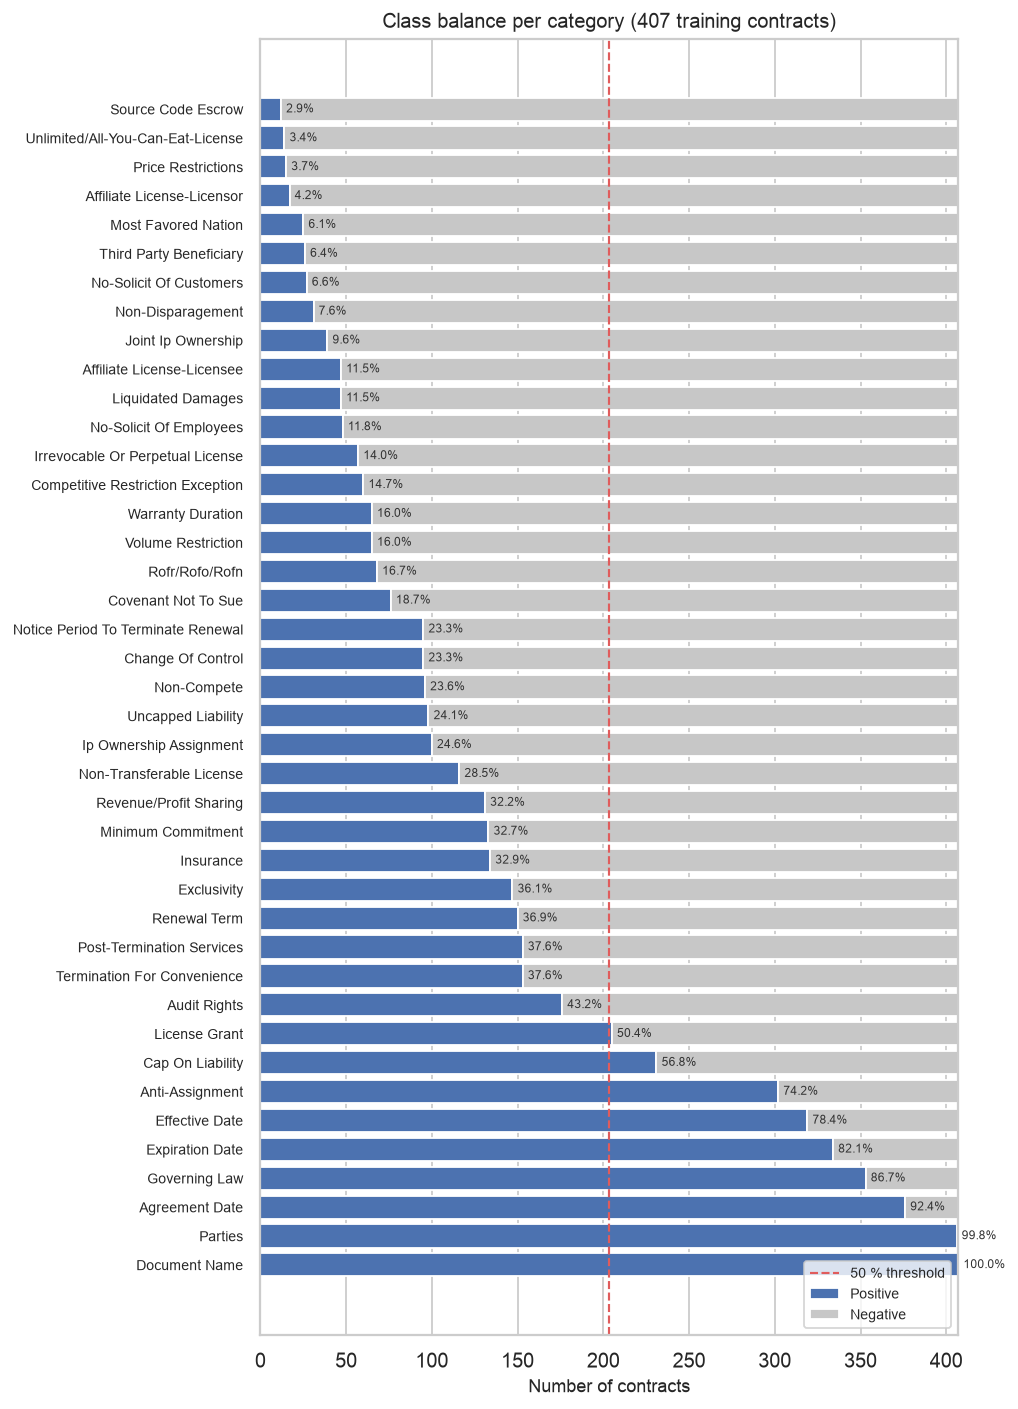

In [17]:
pos = train_labels.sum().rename("positives")
neg = (N_TRAIN - pos).rename("negatives")
ratio = (pos / N_TRAIN).rename("pos_ratio")

balance_df = pd.concat([pos, neg, ratio], axis=1).sort_values("positives", ascending=False)
balance_df["pos_pct"] = (balance_df["pos_ratio"] * 100).round(1)

# stacked horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 11))

cats = balance_df.index.tolist()
y = np.arange(len(cats))

ax.barh(y, balance_df["positives"],  color="#4C72B0", label="Positive")
ax.barh(y, balance_df["negatives"], left=balance_df["positives"], color="#C7C7C7", label="Negative")

ax.axvline(N_TRAIN / 2, color="#E05C5C", lw=1.2, ls="--", label="50 % threshold")

ax.set_yticks(y)
ax.set_yticklabels(cats, fontsize=8)
ax.set_xlabel("Number of contracts")
ax.set_title("Class balance per category (407 training contracts)")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(0, N_TRAIN)

# annotate positive % on each bar
for i, row in enumerate(balance_df.itertuples()):
    ax.text(row.positives + 3, i, f"{row.pos_pct}%", va="center", fontsize=6.5, color="#333")

plt.tight_layout()
plt.show()

In [18]:
# Summary table — flag severely imbalanced categories
SPARSE_THRESHOLD = 0.05   # <5% positive  → too few positives
SATURATED_THRESHOLD = 0.99  # >99% positive → too few negatives

balance_df["flag"] = ""
balance_df.loc[balance_df["pos_ratio"] < SPARSE_THRESHOLD, "flag"] = "sparse"
balance_df.loc[balance_df["pos_ratio"] > SATURATED_THRESHOLD, "flag"] = "saturated"

print("Sparse categories (<5% positive):")
display(balance_df[balance_df["flag"] == "sparse"][["positives", "negatives", "pos_pct"]])

print("\nSaturated categories (>99% positive, almost no negatives):")
display(balance_df[balance_df["flag"] == "saturated"][["positives", "negatives", "pos_pct"]])

Sparse categories (<5% positive):


,positives,negatives,pos_pct
category,,,
Affiliate License-Licensor,17,390,4.2
Price Restrictions,15,392,3.7
Unlimited/All-You-Can-Eat-License,14,393,3.4
Source Code Escrow,12,395,2.9



Saturated categories (>99% positive, almost no negatives):


,positives,negatives,pos_pct
category,,,
Document Name,407,0,100.0
Parties,406,1,99.8


---
## 3.3 Label co-occurrence

Which categories tend to appear together in the same contract?  
We compute the **Jaccard similarity** between each pair: J(A,B) = |A ∩ B| / |A ∪ B| and use that information to print the **top 20 co-occurring pairs** by raw count.

In [19]:
# Contract-level co-occurrence: how many contracts contain both categories
cooc = train_labels.T.dot(train_labels)

# Jaccard similarity:  J(A,B) = |A and B| / |A or B|
pos_counts = train_labels.sum()
union = pos_counts.values[:, None] + pos_counts.values[None, :] - cooc.values
jaccard_df = pd.DataFrame(cooc.values / union, index=cooc.index, columns=cooc.columns)

# Top 20 co-occurring pairs by raw count (excluding same-category diagonal)
cooc_pairs = []
cats_list = cooc.index.tolist()
for i in range(len(cats_list)):
    for j in range(i + 1, len(cats_list)):
        a, b = cats_list[i], cats_list[j]
        count = int(cooc.loc[a, b])
        j_score = float(jaccard_df.loc[a, b])
        cooc_pairs.append({"cat_a": a, "cat_b": b, "both": count, "jaccard": round(j_score, 3)})

cooc_pairs_df = pd.DataFrame(cooc_pairs).sort_values("both", ascending=False)
print("Top 20 category pairs by co-occurrence count:")
display(cooc_pairs_df.head(20).reset_index(drop=True))

Top 20 category pairs by co-occurrence count:


,cat_a,cat_b,both,jaccard
0,Document Name,Parties,406,0.998
1,Agreement Date,Parties,376,0.926
2,Agreement Date,Document Name,376,0.924
3,Document Name,Governing Law,353,0.867
4,Governing Law,Parties,352,0.865
5,Document Name,Expiration Date,334,0.821
6,Expiration Date,Parties,334,0.823
7,Agreement Date,Governing Law,332,0.836
8,Effective Date,Parties,319,0.786
9,Document Name,Effective Date,319,0.784


---
## 3.4 Clause length distribution

Each row in `train_clauses` is an annotated span. We look at:
- Character length of each span
- Word count of each span
- How these vary across categories (some categories extract long narrative clauses; others extract short date strings or proper names)

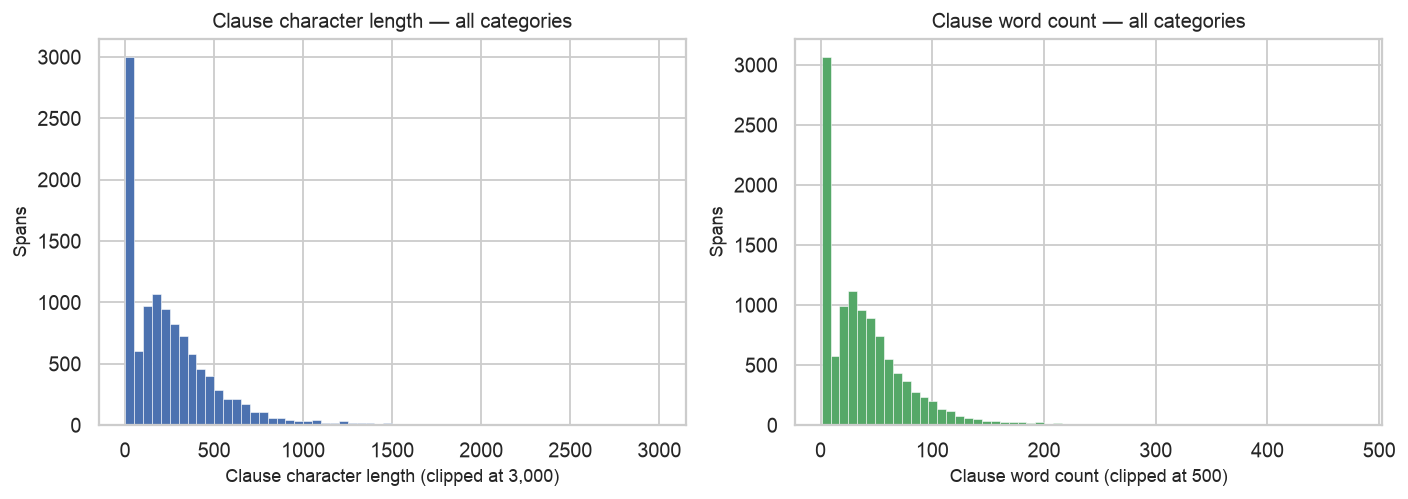

       char_len  word_count
count   11166.0     11166.0
mean      264.2        40.9
std       287.5        43.5
min         1.0         1.0
25%        38.2         6.0
50%       197.5        31.0
75%       368.0        57.0
max      3884.0       479.0


In [20]:
train_clauses = train_clauses.copy()
train_clauses["char_len"]  = train_clauses["clause_text"].str.len()
train_clauses["word_count"] = train_clauses["clause_text"].str.split().str.len()

# Overall distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(train_clauses["char_len"].clip(upper=3000), bins=60, color="#4C72B0", edgecolor="white", lw=0.3)
axes[0].set_xlabel("Clause character length (clipped at 3,000)")
axes[0].set_ylabel("Spans")
axes[0].set_title("Clause character length — all categories")

axes[1].hist(train_clauses["word_count"].clip(upper=500), bins=60, color="#55A868", edgecolor="white", lw=0.3)
axes[1].set_xlabel("Clause word count (clipped at 500)")
axes[1].set_ylabel("Spans")
axes[1].set_title("Clause word count — all categories")

plt.tight_layout()
plt.show()

print(train_clauses[["char_len", "word_count"]].describe().round(1))

/var/folders/9x/mzys1ql16vqg_8q3bmczfc_40000gn/T/ipykernel_84891/2781587716.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)


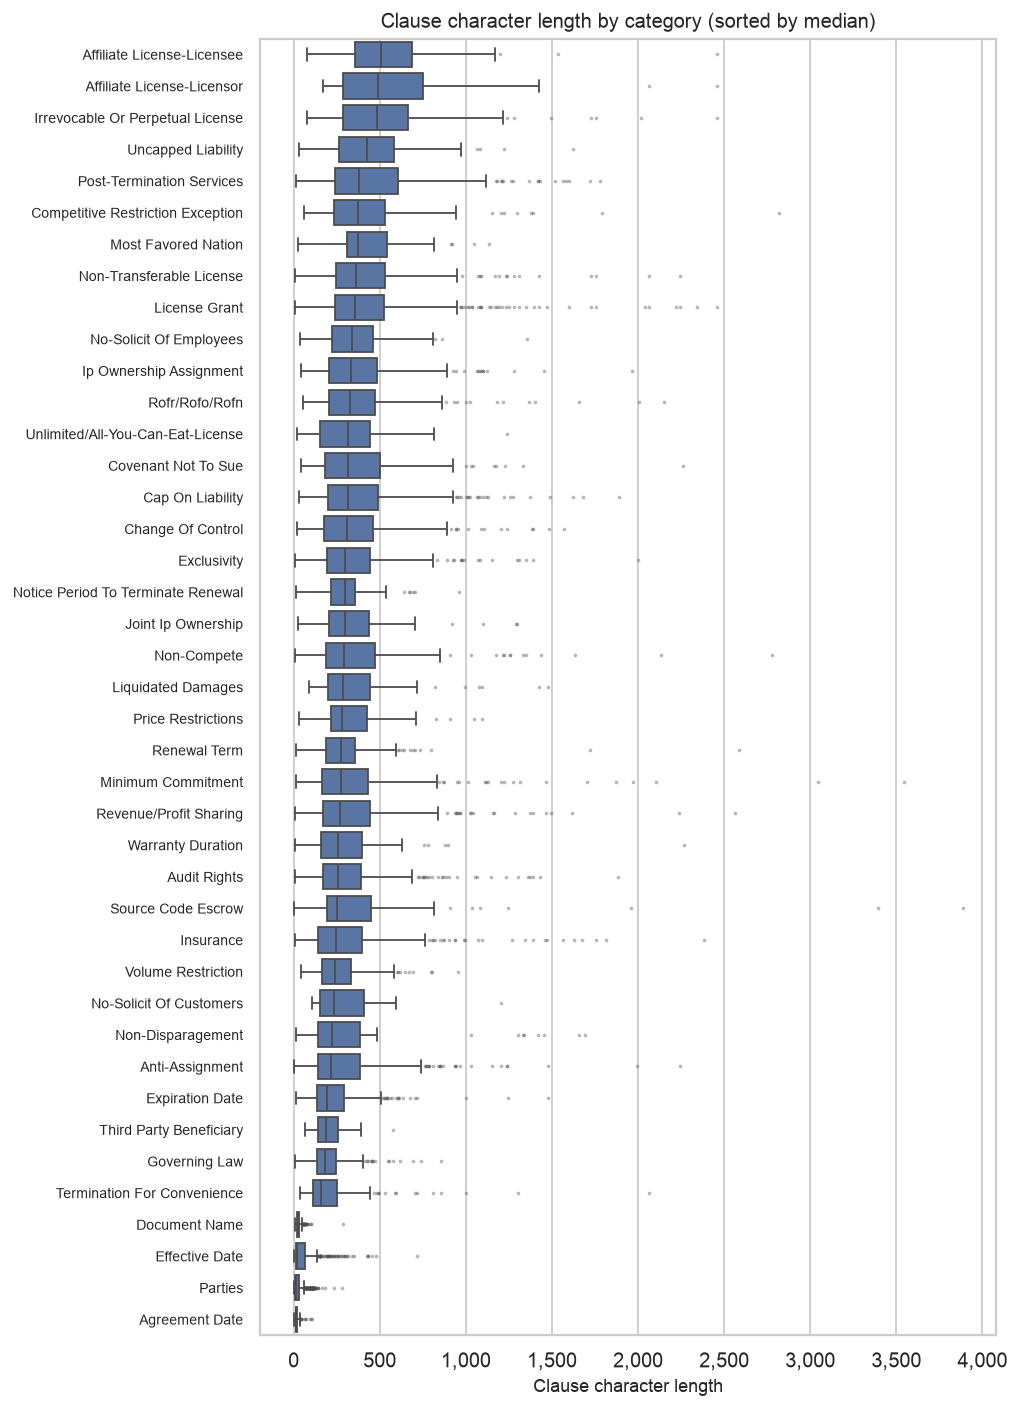

In [21]:
# Per-category box plot of clause character length - sorted by median
cat_median_order = (
    train_clauses.groupby("category")["char_len"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(8, 11))
sns.boxplot(
    data=train_clauses,
    x="char_len",
    y="category",
    order=cat_median_order,
    color="#4C72B0",
    flierprops={"marker": ".", "markersize": 2, "alpha": 0.4},
    ax=ax,
)
ax.set_xlabel("Clause character length")
ax.set_ylabel("")
ax.set_title("Clause character length by category (sorted by median)")
ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

In [22]:
# Percentile summary per category
clause_stats = (
    train_clauses.groupby("category")["char_len"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95])
    .round(0)
    .astype(int)
    .sort_values("50%", ascending=False)
)
print("Clause character length percentiles per category:")
display(clause_stats)

Clause character length percentiles per category:


,count,mean,std,min,25%,50%,75%,95%,max
category,,,,,,,,,
Affiliate License-Licensee,88,566,339,76,358,505,686,1126,2457
Affiliate License-Licensor,49,601,453,171,284,489,752,1333,2457
Irrevocable Or Perpetual License,142,540,374,75,287,484,664,1215,2457
Uncapped Liability,151,448,248,33,262,427,580,883,1624
Post-Termination Services,368,465,319,12,240,378,607,1103,1778
Competitive Restriction Exception,98,469,405,62,233,374,529,1231,2820
Most Favored Nation,35,452,256,26,310,371,539,957,1136
Non-Transferable License,255,435,317,9,244,361,530,1072,2246
License Grant,642,431,313,9,240,358,524,978,2457


---
## 3.5 Contract length distribution

Each contract is the full text of a legal agreement. Length matters for deciding how to chunk contracts before passing them to a classifier: very long contracts may need to be split; very short ones may be entire agreements that fit in a single window.

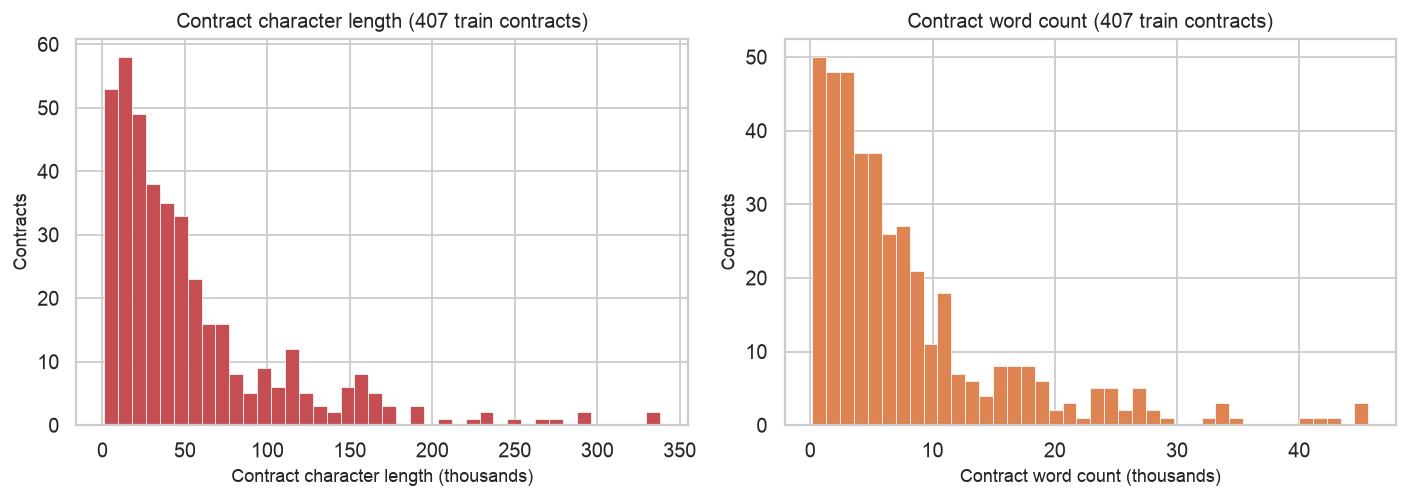

       char_len  word_count
count       407         407
mean      54095        8060
std       56015        8305
min        1081         170
25%       16682        2568
50%       36019        5369
75%       68676       10448
max      338211       45650


In [23]:
train_contracts = train_contracts.copy()
train_contracts["char_len"]  = train_contracts["text"].str.len()
train_contracts["word_count"] = train_contracts["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(train_contracts["char_len"] / 1000, bins=40, color="#C44E52", edgecolor="white", lw=0.4)
axes[0].set_xlabel("Contract character length (thousands)")
axes[0].set_ylabel("Contracts")
axes[0].set_title("Contract character length (407 train contracts)")

axes[1].hist(train_contracts["word_count"] / 1000, bins=40, color="#DD8452", edgecolor="white", lw=0.4)
axes[1].set_xlabel("Contract word count (thousands)")
axes[1].set_ylabel("Contracts")
axes[1].set_title("Contract word count (407 train contracts)")

plt.tight_layout()
plt.show()

print(train_contracts[["char_len", "word_count"]].describe().round(0).astype(int))

In [24]:
# Flag outliers: very short and very long contracts
SHORT_THRESHOLD = 5_000   # chars
LONG_THRESHOLD  = 200_000 # chars

short = train_contracts[train_contracts["char_len"] < SHORT_THRESHOLD]
long  = train_contracts[train_contracts["char_len"] > LONG_THRESHOLD]

print(f"Short contracts (<{SHORT_THRESHOLD:,} chars): {len(short)}")
if len(short):
    display(short[["contract_id", "char_len", "word_count"]].sort_values("char_len"))

print(f"\nLong contracts (>{LONG_THRESHOLD:,} chars): {len(long)}")
if len(long):
    display(long[["contract_id", "char_len", "word_count"]].sort_values("char_len", ascending=False).head(10))

Short contracts (<5,000 chars): 26


,contract_id,char_len,word_count
2,NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT,1081,170
54,"VIRGINGALACTICHOLDINGS,INC_04_08_2020-EX-99.1-...",1194,188
169,BLACKROCKMUNIHOLDINGSINVESTMENTQUALITYFUND_04_...,1283,201
366,"MACY_S,INC_05_11_2020-EX-99.4-JOINT FILING AGR...",1397,216
218,"SPRINGBANKPHARMACEUTICALS,INC_04_08_2020-EX-99...",1556,246
36,GALACTICOMMTECHNOLOGIESINC_11_07_1997-EX-10.46...,1660,223
384,BellringBrandsInc_20190920_S-1_EX-10.12_118170...,1742,258
378,GluMobileInc_20070319_S-1A_EX-10.09_436630_EX-...,1902,291
249,UNITEDNATIONALBANCORP_03_03_1999-EX-99-Outsour...,1952,279
87,BANGIINC_05_25_2005-EX-10-Premium Managed Host...,2010,302



Long contracts (>200,000 chars): 11


,contract_id,char_len,word_count
358,MANUFACTURERSSERVICESLTD_06_05_2000-EX-10.14-O...,338211,41962
157,"CERES,INC_01_25_2012-EX-10.20-Collaboration Ag...",335282,45577
151,PhasebioPharmaceuticalsInc_20200330_10-K_EX-10...,291873,45650
43,VerizonAbsLlc_20200123_8-K_EX-10.4_11952335_EX...,289615,45143
209,"Array BioPharma Inc. - LICENSE, DEVELOPMENT AN...",272018,42742
213,RevolutionMedicinesInc_20200117_S-1_EX-10.1_11...,266213,40936
136,MRSFIELDSORIGINALCOOKIESINC_01_29_1998-EX-10-F...,249359,33705
72,AzulSa_20170303_F-1A_EX-10.3_9943903_EX-10.3_M...,233248,34155
117,AtnInternationalInc_20191108_10-Q_EX-10.1_1187...,228943,34973
59,UpjohnInc_20200121_10-12G_EX-2.6_11948692_EX-2...,225094,33948


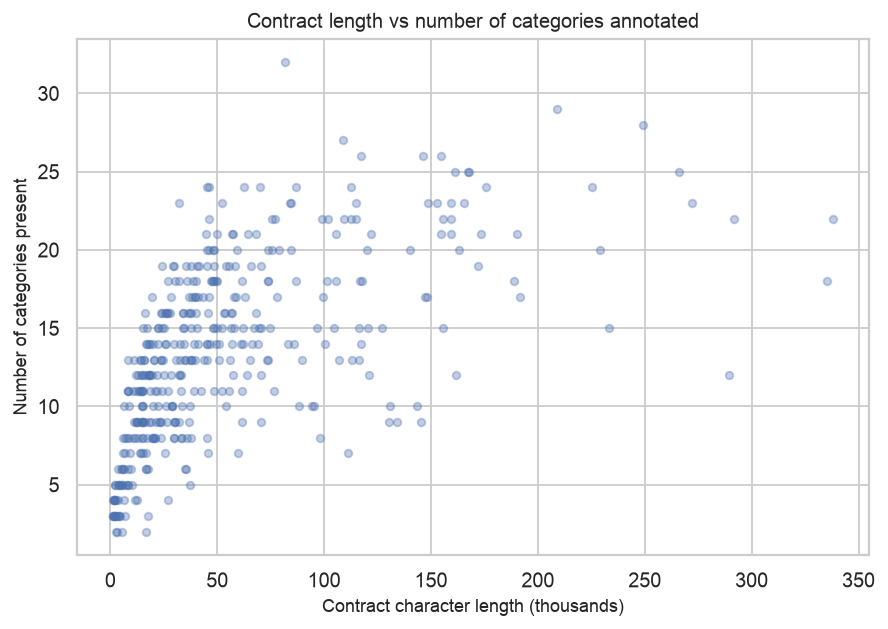

Pearson correlation (length vs n_categories): 0.599


In [25]:
# Scatter: contract length vs number of categories present
label_counts = train_labels.sum(axis=1).rename("n_categories")
scatter_df = train_contracts.set_index("contract_id").join(label_counts)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    scatter_df["char_len"] / 1000,
    scatter_df["n_categories"],
    alpha=0.35, s=18, color="#4C72B0",
)
ax.set_xlabel("Contract character length (thousands)")
ax.set_ylabel("Number of categories present")
ax.set_title("Contract length vs number of categories annotated")
plt.tight_layout()
plt.show()

corr = scatter_df[["char_len", "n_categories"]].corr().loc["char_len", "n_categories"]
print(f"Pearson correlation (length vs n_categories): {corr:.3f}")

---
## 3.6 Summary

### What this notebook does and why it matters

**Goal:** Characterise the class imbalance and structural properties of the CUAD training set before choosing a modelling strategy.

---

#### 1. Positive counts per category

We counted how many of the 407 training contracts contain at least one annotated span for each of the 41 categories, then visualised the positive/negative split as a stacked bar chart.

**Why it matters:** CUAD is severely imbalanced. The top two categories (*Document Name*, *Parties*) appear in essentially every contract, so a classifier can score near-perfect accuracy on them by predicting positive for everything. At the other extreme, four categories (*Source Code Escrow*, *Unlimited License*, *Price Restrictions*, *Affiliate License-Licensor*) appear in fewer than 5% of contracts - a model that always predicts negative gets 95%+ accuracy there. Standard accuracy is therefore a useless metric; this plot motivates using precision/recall/F1 per category and class-weighted or focal loss during training.

---

#### 2. Label co-occurrence

We compute the Jaccard similarity pairs and list the top 20 co-occurring pairs by raw count.

**Why it matters:** High co-occurrence can mean two things:
- *Legal pairing* - some clauses almost always come as a set (e.g. *Uncapped Liability* and *Cap on Liability* in the same contract). Worth knowing which pairs are near-redundant when deciding whether to merge or drop categories.
- *Spurious signal* - if two categories almost always co-occur, a model might learn to fire on category B simply because it saw category A, rather than reading the actual clause. The pairs table is the first thing to check during error analysis if a category is being systematically confused with another.

---

#### 3. Clause length distribution

We measure the character length and word count of each annotated span in `train_clauses`, show overall histograms, and break down the distribution per category with a box plot sorted by median.

**Why it matters:** Clause length will affect chunking strategy. Extraction categories like *Document Name* or *Agreement Date* produce spans of under 20 characters; liability and restriction categories produce spans of hundreds or thousands of characters. A fixed-size chunk will sometimes split a clause in half - knowing which categories have the longest spans tells us where that risk is highest. It also informs the minimum context window a model needs to reliably detect each category.

---

#### 4. Contract length distribution

We measure the character length and word count of each full contract text, visualise the distribution, and flag outliers (very short or very long contracts). We also scatter contract length against the number of categories annotated.

**Why it matters:** Most transformer models have a fixed maximum input length (e.g. 512 tokens for BERT, 4096 for Longformer). Contracts in CUAD range from a few thousand to over 200,000 characters - the median is around 35,000 characters, far longer than any standard transformer window.

---

# 4. Category selection

Step 1: **Analyze category support** count positive/negative examples per category and identify
categories with too few/many examples for reliable training/evaluation.

Works from `train_labels` only (never the test split), so this decision does not
peek at test data.

Working from the frames built above:

- `train_labels` — contract x category multi-hot matrix (post-cleaning, 407 contracts)
- `train_clauses` — one row per annotated span, used below to read example clauses

We use `train_labels` only, not the test split, so this label-selection decision does not peek at test data.

## 4.1 Category support

Section 3.2 already counted positives and negatives per category across the 407 cleaned
training contracts, so this section does not recompute them - it reuses `balance_df` and
renames the columns.

Worth being explicit about, because it was previously obscured by having two tables: the
`MIN_SUPPORT = 20` contract cut used below and section 3.2's 5% cut are the *same cut*
(20/407 = 4.9%). They flag the same categories. Section 3 is the evidence; this section is
only the decision.

In [26]:
n_contracts = len(train_contracts)

support = (
    balance_df[["positives", "negatives", "pos_pct"]]
    .rename(columns={"positives": "n_contracts",
                     "negatives": "n_neg",
                     "pos_pct": "pct_contracts"})
)

support

,n_contracts,n_neg,pct_contracts
category,,,
Document Name,407,0,100.0
Parties,406,1,99.8
Agreement Date,376,31,92.4
Governing Law,353,54,86.7
Expiration Date,334,73,82.1
Effective Date,319,88,78.4
Anti-Assignment,302,105,74.2
Cap On Liability,231,176,56.8
License Grant,205,202,50.4


## 4.2 Flag sparse categories

`MIN_SUPPORT` is a starting threshold, not a final answer. raise/lower it and see how
the sparse list changes before recommending anything to the team (step 4 of the issue).

In [27]:
MIN_SUPPORT = 20  # contracts; revisit this threshold before finalizing

support["sparse"] = support["n_contracts"] < MIN_SUPPORT

print(f"{support['sparse'].sum()} of {len(support)} categories fall below MIN_SUPPORT={MIN_SUPPORT}:")
support[support["sparse"]]

4 of 41 categories fall below MIN_SUPPORT=20:


,n_contracts,n_neg,pct_contracts,sparse
category,,,,
Affiliate License-Licensor,17,390,4.2,True
Price Restrictions,15,392,3.7,True
Unlimited/All-You-Can-Eat-License,14,393,3.4,True
Source Code Escrow,12,395,2.9,True


## 4.3 Negative support check

Checking positive count alone misses the opposite failure mode: a category present in
almost every contract has almost no *negative* examples, so precision/recall on "this
clause is absent" is just as unreliable to estimate. A 2026 CUAD audit ([Tekin,
*Abstention Errors and Segment Support in CUAD*](https://arxiv.org/abs/2609.13274)) makes
this point directly: using a combined threshold (>= N positive AND >= N negative
contracts), only 9 of 41 categories pass at N=30, and 18 pass at N=20.

We reuse `MIN_SUPPORT` and flag on *either* side being too thin.

In [28]:
# n_neg already came from balance_df; just apply the same threshold to the other side
support["sparse_neg"] = support["n_neg"] < MIN_SUPPORT
support["sparse_either"] = support["sparse"] | support["sparse_neg"]

print(f"{support['sparse_either'].sum()} of {len(support)} categories are thin on "
      f"positives, negatives, or both:")
support[support["sparse_either"]]

6 of 41 categories are thin on positives, negatives, or both:


,n_contracts,n_neg,pct_contracts,sparse,sparse_neg,sparse_either
category,,,,,,
Document Name,407,0,100.0,False,True,True
Parties,406,1,99.8,False,True,True
Affiliate License-Licensor,17,390,4.2,True,False,True
Price Restrictions,15,392,3.7,True,False,True
Unlimited/All-You-Can-Eat-License,14,393,3.4,True,False,True
Source Code Escrow,12,395,2.9,True,False,True


## 4.4 Manual read: any merge candidates?

High co-occurrence (see section 3.3) and CUAD's own "Group"
column in `category_descriptions.csv` cluster some categories together (e.g. the date
fields, the license-grant family, Uncapped/Cap on Liability). Co-occurring isn't the same
as redundant, though, so before proposing any merge we read actual annotated spans for the
4 rarest categories to check whether they're conceptually distinct from each other and
from other categories, or just noisy/overlapping restatements.

In [29]:
RAREST_CATS = ["Affiliate License-Licensor", "Price Restrictions",
               "Unlimited/All-You-Can-Eat-License", "Source Code Escrow"]

for cat in RAREST_CATS:
    print(f"=== {cat} ===")
    examples = train_clauses.loc[train_clauses["category"] == cat, "clause_text"].head(3)
    for ex in examples:
        print(" -", ex[:200].replace("\n", " "))
    print()

=== Affiliate License-Licensor ===
 - Subject to the restrictions set out in Section 2.2, ENERGOUS hereby grants to DIALOG a non-exclusive (subject to Section 2.5), irrevocable, worldwide, sub-licensable (solely in accordance with Section
 - "Product IP" means (a) all Intellectual Property Rights in and to the Products, including all Product Updates, (b) any other Inventions and work products created or developed in connection with resear
 - "Customer Property" means all Intellectual Property, together with all materials, data, writings and other property in any form whatsoever, which is (a) owned or controlled by Customer or its Affiliat

=== Price Restrictions ===
 - The Company  also  reserves  the right to                            increase  or  decrease  the price  per unit  based on                            Company   wide   changes   in  unit   prices  to  
 - The prices set forth in                            Section   2.4(a)  shall  be  subject  to   adjustment              

**Finding: Nothing we could merge.** Reading the spans, all four rarest categories are
distinct: affiliate IP grants (Licensor), pricing-adjustment mechanics,
unlimited-usage license terms, and source-code escrow arrangements, and none overlap in
wording with each other or with a more common category. The same holds when reading the
CSV descriptions for the other official "Group" clusters (e.g. Uncapped Liability and Cap
on Liability are complementary, not duplicate; Affiliate License-Licensor vs -Licensee
differ by *which party's* affiliates are covered). Co occurrence in `category_descriptions.csv`
reflects clauses that tend to appear in the same contracts, not conceptual redundancy, so
I **wouldn't** recommending any merges from this EDA alone.

**Working conclusion for step 1 (pending input on legal value):**
- Rarest categories (regardless of exact `MIN_SUPPORT` cutoff): `Affiliate License-Licensor`,
  `Price Restrictions`, `Unlimited/All-You-Can-Eat-License`, `Source Code Escrow`.
- No merges identified.

## 4.5 Apply the drop decision

Three separate reasons a category might not belong in the reported numbers, and they need
different treatment:

1. **Not measurable at all.** `Price Restrictions` has positive contracts in train and
   **zero** in the official test split, so no precision, recall or F1 exists for it at any
   threshold. Already removed in section 2.3; the cell below only asserts it is gone, so a
   future change to the splits cannot silently reintroduce an unscoreable column.
2. **Thin but measurable.** The other three rarest categories do have test positives.
   Dropping them trades coverage for score stability, which is a question about legal value
   rather than statistics, so it stays with the CA. `PENDING_CA_APPROVAL = True` keeps them
   in; flip it to `False` once we have an answer.
3. **Trivially predictable.** `Document Name` (407/407) and `Parties` (406/407) appear in
   essentially every contract, so they have almost no negatives and a model scores near 1.0
   on them for free. Leaving them inside a macro-average silently inflates it. They stay in
   the model but are excluded from `EVAL_CATEGORIES` and reported on their own.

The output of this cell is the contract that every downstream model has to honour:
`final_categories` is what gets predicted, `EVAL_CATEGORIES` is what gets averaged. Without
fixing both, the TF-IDF baseline (#12) and the transformer (#19) end up averaging over
different denominators and the comparison between them means nothing.

In [30]:
# 1. Unevaluable categories were already removed in section 2.3. Re-check rather than
#    trust it: crosstab omits an absent category entirely, so reindex to catch both
#    "missing from test" and "present but all-zero".
test_pos = test_labels.sum().reindex(train_labels.columns, fill_value=0)
NOT_EVALUABLE = test_pos.index[test_pos == 0].tolist()
assert not NOT_EVALUABLE, f"unevaluable categories survived cleaning: {NOT_EVALUABLE}"

# 2. thin but measurable -> the CA's call, kept until we hear back
DROP_CANDIDATES = ["Affiliate License-Licensor",
                   "Unlimited/All-You-Can-Eat-License",
                   "Source Code Escrow"]
PENDING_CA_APPROVAL = True

# 3. no meaningful negatives -> predicted, but never averaged into macro-F1
TRIVIAL = ["Document Name", "Parties"]

final_categories = [c for c in train_labels.columns if c not in NOT_EVALUABLE]
if not PENDING_CA_APPROVAL:
    final_categories = [c for c in final_categories if c not in DROP_CANDIDATES]

EVAL_CATEGORIES = [c for c in final_categories if c not in TRIVIAL]

final_train_labels = train_labels[final_categories]
final_test_labels = test_labels.reindex(columns=final_categories, fill_value=0)

print("removed upstream in 2.3 (0 test positives):", NO_TEST_SUPPORT)
print("kept, pending CA decision:                ", DROP_CANDIDATES)
print("kept but excluded from macro-F1:          ", TRIVIAL)
print(f"\nlabel columns predicted : {len(final_categories)}")
print(f"categories in macro-F1  : {len(EVAL_CATEGORIES)}")

final_train_labels.shape, final_test_labels.shape

removed, not evaluable (0 test positives): ['Price Restrictions']
kept, pending CA decision:                 ['Affiliate License-Licensor', 'Unlimited/All-You-Can-Eat-License', 'Source Code Escrow']
kept but excluded from macro-F1:           ['Document Name', 'Parties']

label columns predicted : 40
categories in macro-F1  : 38


((407, 40), (102, 40))

---

# 5. Chunking strategy

The goal of this analysis is to select a chunk window size and overlap that preserve annotated CUAD clauses while keeping chunks small enough for transformer-based classification.

In [31]:
longest_clauses = train_clauses.nlargest(
    10, "char_len"
)[
    ["category", "clause_text", "char_len"]
]

longest_clauses

,category,clause_text,char_len
7711,Source Code Escrow,Storage Fee (payable if the source code exceed...,3884
3850,Minimum Commitment,- --------------------------------------------...,3546
7708,Source Code Escrow,Subject to the provisions of Clauses 6.2 and 6...,3393
3848,Minimum Commitment,- --------------------------------------------...,3043
10427,Competitive Restriction Exception,Upon the effective date of this agreement COMW...,2820
1244,Non-Compete,The Executive agrees and undertakes with the C...,2780
4540,Renewal Term,You have the right to renew the franchise for ...,2586
9516,Revenue/Profit Sharing,In further consideration for the Service and t...,2563
5612,License Grant,"Subject to Section 3.2, a Licensor Party, on b...",2457
5616,Affiliate License-Licensor,"Subject to Section 3.2, a Licensor Party, on b...",2457


In [32]:
tokenizer = AutoTokenizer.from_pretrained("distilroberta-base")

In [33]:
train_clauses["token_length"] = train_clauses["clause_text"].apply(
    lambda text: len(
        tokenizer.encode(text, add_special_tokens=False)
    )
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (524 > 512). Running this sequence through the model will result in indexing errors


In [34]:
train_clauses["token_length"].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
)

count    11166.000000
mean        60.776464
std         75.757942
min          1.000000
50%         41.000000
75%         82.000000
90%        136.000000
95%        184.000000
99%        345.000000
max       1989.000000
Name: token_length, dtype: float64

In [35]:
thresholds = [128, 256, 384, 510, 512]

for threshold in thresholds:
    count = (train_clauses["token_length"] > threshold).sum()
    percent = count / len(train_clauses) * 100
    
    print(
        f"Over {threshold:3} tokens: "
        f"{count:4} clauses ({percent:.2f}%)"
    )

Over 128 tokens: 1246 clauses (11.16%)
Over 256 tokens:  249 clauses (2.23%)
Over 384 tokens:   59 clauses (0.53%)
Over 510 tokens:   26 clauses (0.23%)
Over 512 tokens:   26 clauses (0.23%)


### Candidate Chunking Strategy

DistilRoBERTa supports a maximum sequence length of 512 tokens and requires
2 special tokens, leaving 510 tokens for contract text. Candidate overlap
sizes will be evaluated based on full annotation coverage and the number of
chunks generated.

In [36]:
def chunk_contract(text, window_size=510, overlap=128):
    encoding = tokenizer(
        text,
        add_special_tokens=False,
        return_offsets_mapping=True
    )

    token_ids = encoding["input_ids"]
    offsets = encoding["offset_mapping"]

    step = window_size - overlap

    chunks = []

    for token_start in range(0, len(token_ids), step):
        token_end = min(token_start + window_size, len(token_ids))

        chunk_ids = token_ids[token_start:token_end]
        chunk_offsets = offsets[token_start:token_end]

        if not chunk_ids:
            break

        char_start = chunk_offsets[0][0]
        char_end = chunk_offsets[-1][1]

        chunks.append({
            "token_start": token_start,
            "token_end": token_end,
            "char_start": char_start,
            "char_end": char_end,
            "text": text[char_start:char_end]
        })

        if token_end == len(token_ids):
            break

    return chunks

In [37]:
def evaluate_chunking_detailed(contracts, clauses, window_size, overlap):
    total_chunks = 0
    fully_covered = 0
    too_long = 0
    boundary_failures = 0

    chunks_by_contract = {}

    for _, contract in contracts.iterrows():
        contract_id = contract["contract_id"]

        chunks = chunk_contract(
            contract["text"],
            window_size=window_size,
            overlap=overlap
        )

        chunks_by_contract[contract_id] = chunks
        total_chunks += len(chunks)

    for _, clause in clauses.iterrows():

        # This clause cannot physically fit in the selected window.
        if clause["token_length"] > window_size:
            too_long += 1
            continue

        contract_chunks = chunks_by_contract[clause["contract_id"]]

        covered = any(
            chunk["char_start"] <= clause["start"]
            and clause["end"] <= chunk["char_end"]
            for chunk in contract_chunks
        )

        if covered:
            fully_covered += 1
        else:
            boundary_failures += 1

    eligible = len(clauses) - too_long

    return {
        "overlap": overlap,
        "total_chunks": total_chunks,
        "too_long": too_long,
        "boundary_failures": boundary_failures,
        "eligible_clauses": eligible,
        "eligible_covered": fully_covered,
        "eligible_coverage_percent":
            fully_covered / eligible * 100
    }

### Choose the Overlap

Overlaps from 128 to 288 tokens are compared on the measure that actually matters: how many
annotated clauses land *entirely* inside at least one chunk. Annotations longer than the
510-token window are counted separately, since no overlap setting can fix those - that
separates a limitation of the model's input size from a limitation of where we cut.

In [38]:
candidate_overlaps = [128, 160, 192, 224, 256, 288]

detailed_results = []

for overlap in candidate_overlaps:
    detailed_results.append(
        evaluate_chunking_detailed(
            train_contracts,
            train_clauses,
            window_size=510,
            overlap=overlap
        )
    )

detailed_df = pd.DataFrame(detailed_results)

detailed_df

,overlap,total_chunks,too_long,boundary_failures,eligible_clauses,eligible_covered,eligible_coverage_percent
0,128,14174,26,222,11140,10918,98.007181
1,160,15412,26,155,11140,10985,98.608618
2,192,16910,26,116,11140,11024,98.958707
3,224,18716,26,96,11140,11044,99.138241
4,256,20997,26,58,11140,11082,99.479354
5,288,23939,26,39,11140,11101,99.649910


### Selected Chunking Parameters

We selected a **510-token text window with 256-token overlap**.

DistilRoBERTa has a maximum input length of 512 tokens and requires 2
special tokens, leaving 510 tokens available for contract text.

Clause-length analysis showed that only 26 of 11,166 training annotations
(0.23%) exceed 510 tokens and therefore cannot be fully represented within
a single model input.

Among the remaining 11,140 eligible annotations, a 256-token overlap
preserved 11,082 clauses entirely within at least one chunk, corresponding
to **99.48% eligible full-span coverage**.

Increasing overlap to 288 tokens improved eligible coverage only to 99.65%
while increasing the number of generated chunks from 20,997 to 23,939.
Therefore, 256 tokens was selected as a practical tradeoff between
annotation preservation and computational redundancy.

In [39]:
def find_boundary_failures(contracts, clauses, window_size=510, overlap=256):
    chunks_by_contract = {}

    for _, contract in contracts.iterrows():
        chunks_by_contract[contract["contract_id"]] = chunk_contract(
            contract["text"],
            window_size=window_size,
            overlap=overlap
        )

    failures = []

    for _, clause in clauses.iterrows():

        # Handle clauses that cannot physically fit separately
        if clause["token_length"] > window_size:
            continue

        chunks = chunks_by_contract[clause["contract_id"]]

        covered = any(
            chunk["char_start"] <= clause["start"]
            and clause["end"] <= chunk["char_end"]
            for chunk in chunks
        )

        if not covered:
            failures.append(clause)

    return pd.DataFrame(failures)

In [40]:
boundary_failures_df = find_boundary_failures(
    train_contracts,
    train_clauses
)

print("Boundary failures:", len(boundary_failures_df))

boundary_failures_df[
    ["category", "token_length", "char_len"]
].sort_values(
    "token_length",
    ascending=False
).head(20)

Boundary failures: 58


,category,token_length,char_len
765,Cap On Liability,507,1275
4230,License Grant,492,2246
4232,Non-Transferable License,492,2246
4348,Rofr/Rofo/Rofn,488,2152
7827,Revenue/Profit Sharing,479,1388
4919,Covenant Not To Sue,468,2263
3732,Exclusivity,465,1999
2567,Minimum Commitment,463,2102
10607,Anti-Assignment,455,2242
6834,Minimum Commitment,445,1271


## 5.1 Map Annotation Spans onto Chunks

Each generated chunk is assigned all CUAD clause categories whose annotated
spans are fully contained within the chunk. Because multiple clause categories
may occur in the same chunk, labels are stored as multi-label category lists. A category is assigned only when the annotation is fully contained within
the chunk. Partial-span intersections are not labeled because doing so could
associate a category with a chunk that does not contain the complete
annotated clause.

In [41]:
def build_labeled_chunks(contracts, clauses, window_size=510, overlap=256):
    rows = []

    # Group annotations once so we can efficiently retrieve them by contract
    clauses_by_contract = {
        contract_id: group
        for contract_id, group in clauses.groupby("contract_id")
    }

    for _, contract in contracts.iterrows():
        contract_id = contract["contract_id"]
        text = contract["text"]

        chunks = chunk_contract(
            text,
            window_size=window_size,
            overlap=overlap
        )

        contract_clauses = clauses_by_contract.get(contract_id)

        for chunk_id, chunk in enumerate(chunks):
            labels = []

            if contract_clauses is not None:
                for _, clause in contract_clauses.iterrows():

                    # Annotation must be completely inside this chunk
                    if (
                        chunk["char_start"] <= clause["start"]
                        and clause["end"] <= chunk["char_end"]
                    ):
                        labels.append(clause["category"])

            # Remove duplicate categories within the same chunk
            labels = sorted(set(labels))

            rows.append({
    "contract_id": contract_id,
    "chunk_id": chunk_id,
    "token_start": chunk["token_start"],
    "token_end": chunk["token_end"],
    "char_start": chunk["char_start"],
    "char_end": chunk["char_end"],
    "text": chunk["text"],
    "labels": labels
})

    return pd.DataFrame(rows)

In [42]:
train_chunks = build_labeled_chunks(
    train_contracts,
    train_clauses,
    window_size=510,
    overlap=256
)

train_chunks.head()

,contract_id,chunk_id,token_start,token_end,char_start,char_end,text,labels
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,0,0,510,0,1820,EXHIBIT 10.6\n\n ...,"[Agreement Date, Document Name, Parties]"
1,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,1,254,764,735,2408,will be considered Products if Distributor e...,[Exclusivity]
2,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,2,508,1018,1819,2950,D. The Company's Appointment. The Company...,"[Exclusivity, License Grant]"
3,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,3,762,1272,2407,3452,"Market, and Distributor hereby accep...",[]
4,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,4,1016,1526,2949,3967,by such customers ...,[]


In [43]:
print("Total chunks:", len(train_chunks))

print(
    "Chunks with at least one label:",
    train_chunks["labels"].apply(len).gt(0).sum()
)

print(
    "Chunks with no labels:",
    train_chunks["labels"].apply(len).eq(0).sum()
)

print(
    "Chunks with multiple labels:",
    train_chunks["labels"].apply(len).gt(1).sum()
)

Total chunks: 20997
Chunks with at least one label: 7334
Chunks with no labels: 13663
Chunks with multiple labels: 2869


### Verify Annotation-to-Chunk Mapping

Overlapping chunks can contain the same annotation more than once, so the number of labeled
chunks is not expected to equal the number of annotations. What we check instead, in one
pass: that every eligible annotation is fully contained in at least one chunk, **and** that
its CUAD category was actually assigned to a chunk containing it. The two failure modes are
counted separately - a boundary failure means no chunk holds the whole span, a mapping
failure would mean a chunk holds the span but lost the label.

In [44]:
correctly_mapped = 0
mapping_failures = 0
too_long = 0
boundary_failures = 0

for _, clause in train_clauses.iterrows():

    if clause["token_length"] > 510:
        too_long += 1
        continue

    matching_chunks = train_chunks[
        train_chunks["contract_id"] == clause["contract_id"]
    ]

    containing_chunks = matching_chunks[
        (matching_chunks["char_start"] <= clause["start"]) &
        (clause["end"] <= matching_chunks["char_end"])
    ]

    if len(containing_chunks) == 0:
        boundary_failures += 1
        continue

    label_found = containing_chunks["labels"].apply(
        lambda labels: clause["category"] in labels
    ).any()

    if label_found:
        correctly_mapped += 1
    else:
        mapping_failures += 1

print("Correctly mapped:", correctly_mapped)
print("Mapping failures:", mapping_failures)
print("Boundary failures:", boundary_failures)
print("Too long:", too_long)

Correctly mapped: 11082
Mapping failures: 0
Boundary failures: 58
Too long: 26


### Analyze Uncovered Annotations

Uncovered annotations are separated into two cases:

1. **Boundary failures:** annotations containing at most 510 tokens that could
   fit within the model context but are not fully contained by any chunk.
2. **Too-long annotations:** annotations exceeding the 510-token usable model
   window and therefore cannot be represented in full within one
   DistilRoBERTa input.

The distribution of these cases across clause categories is examined before
determining how they should be handled.

In [45]:
# boundary_failures_df was already computed above with the selected parameters.
# Clauses that are too long to fit in a 510-token text window
too_long_df = train_clauses[
    train_clauses["token_length"] > 510
].copy()

print("Boundary failures:", len(boundary_failures_df))
print("Too-long annotations:", len(too_long_df))

Boundary failures: 58
Too-long annotations: 26


In [46]:
print("BOUNDARY FAILURES BY CATEGORY")

display(
    boundary_failures_df["category"]
    .value_counts()
    .to_frame("count")
)

print("\nTOO-LONG ANNOTATIONS BY CATEGORY")

display(
    too_long_df["category"]
    .value_counts()
    .to_frame("count")
)

BOUNDARY FAILURES BY CATEGORY


,count
category,
License Grant,11
Irrevocable Or Perpetual License,6
Minimum Commitment,6
Non-Transferable License,4
Cap On Liability,4
Rofr/Rofo/Rofn,3
Liquidated Damages,3
Ip Ownership Assignment,3
Post-Termination Services,2



TOO-LONG ANNOTATIONS BY CATEGORY


,count
category,
Minimum Commitment,3
License Grant,3
Insurance,2
Non-Compete,2
Affiliate License-Licensor,2
Irrevocable Or Perpetual License,2
Source Code Escrow,2
Revenue/Profit Sharing,2
Post-Termination Services,2


## 5.2 Chunking Validation Summary

The final chunking strategy uses a **510-token text window with 256-token
overlap**. This accommodates DistilRoBERTa's 512-token maximum sequence
length while reserving 2 positions for special tokens.

Across the 11,166 training annotations:

- **11,082 annotations** were fully contained in at least one generated chunk
  and correctly mapped to their CUAD category.
- **58 annotations** were short enough to fit within the model window but
  crossed the boundaries of all generated chunks.
- **26 annotations** exceeded the 510-token usable text window and therefore
  cannot be represented in full within a single DistilRoBERTa input.
- **0 mapping errors** were detected for annotations that were fully
  contained within a chunk.

Among the 11,140 annotations capable of fitting within the model window,
the selected strategy therefore achieves **99.48% full-span coverage**.

The remaining boundary and overlength cases are retained as documented
limitations rather than introducing annotation-aware chunks, which would
use ground-truth span locations unavailable during inference.

## 5.3 Apply Chunking Strategy to Test Set

The chunking parameters were selected using the training data. The same
510-token window and 256-token overlap are now applied unchanged to the
held-out test contracts to avoid using test-set information to tune the
chunking strategy.

In [47]:
test_chunks = build_labeled_chunks(
    test_contracts,
    test_clauses,
    window_size=510,
    overlap=256
)

print("Train chunks:", len(train_chunks))
print("Test chunks:", len(test_chunks))

test_chunks.head()

Train chunks: 20997
Test chunks: 4283


,contract_id,chunk_id,token_start,token_end,char_start,char_end,text,labels
0,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,0,0,510,0,2241,Exhibit 10.16 SUPPLY CONTRACT Contract No: Dat...,"[Document Name, Parties]"
1,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,1,254,764,1052,3447,"""LEHEYUAN""), to purchase the products specifie...",[]
2,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,2,508,1018,2231,4407,subject to the purchase order issued by entrus...,[Insurance]
3,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,3,762,1272,3436,5495,eless paint. 7. DATE OF SHIPMENT: According to...,[Insurance]
4,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,4,1016,1526,4395,6662,Credit shall be valid until 90 days after the ...,[]


### Test Chunk Sanity Checks

The test chunks are checked for labeled, unlabeled, and multi-label examples
to confirm that the same chunk-generation process behaves as expected on
held-out contracts.

In [48]:
print("Total test chunks:", len(test_chunks))

print(
    "Test chunks with at least one label:",
    test_chunks["labels"].apply(len).gt(0).sum()
)

print(
    "Test chunks with no labels:",
    test_chunks["labels"].apply(len).eq(0).sum()
)

print(
    "Test chunks with multiple labels:",
    test_chunks["labels"].apply(len).gt(1).sum()
)

Total test chunks: 4283
Test chunks with at least one label: 1693
Test chunks with no labels: 2590
Test chunks with multiple labels: 662


### Validate Test Annotation Coverage

Test annotations are evaluated using the already-selected chunking parameters.
Annotations exceeding 510 tokens are separated from boundary failures so that
model-length limitations are distinguished from chunk-boundary limitations.

In [49]:
# Calculate token lengths for test annotations
test_clauses["token_length"] = test_clauses["clause_text"].apply(
    lambda text: len(
        tokenizer.encode(
            text,
            add_special_tokens=False
        )
    )
)

test_correctly_mapped = 0
test_mapping_failures = 0
test_boundary_failures = 0
test_too_long = 0

for _, clause in test_clauses.iterrows():

    if clause["token_length"] > 510:
        test_too_long += 1
        continue

    matching_chunks = test_chunks[
        test_chunks["contract_id"] == clause["contract_id"]
    ]

    containing_chunks = matching_chunks[
        (matching_chunks["char_start"] <= clause["start"]) &
        (clause["end"] <= matching_chunks["char_end"])
    ]

    if len(containing_chunks) == 0:
        test_boundary_failures += 1
        continue

    label_found = containing_chunks["labels"].apply(
        lambda labels: clause["category"] in labels
    ).any()

    if label_found:
        test_correctly_mapped += 1
    else:
        test_mapping_failures += 1

print("Total test annotations:", len(test_clauses))
print("Correctly mapped:", test_correctly_mapped)
print("Mapping failures:", test_mapping_failures)
print("Boundary failures:", test_boundary_failures)
print("Too long:", test_too_long)

Total test annotations: 2643
Correctly mapped: 2624
Mapping failures: 0
Boundary failures: 17
Too long: 2


## 5.4 Save Processed Chunk Datasets

The validated train and test chunks are saved for downstream multi-label
classification. Category lists are serialized as JSON strings so that
multi-label assignments can be reconstructed reliably when the CSV files
are loaded. Each chunk also carries the `split` tag from section 2.4, so the fit/validation
boundary stays at the contract level wherever these files are used.

In [50]:
# Tag every chunk with the contract-level split decided in section 2.4, so downstream
# training never has to re-derive it (and can never accidentally split by chunk).
split_by_contract = train_contracts.set_index("contract_id")["split"]
train_chunks["split"] = train_chunks["contract_id"].map(split_by_contract)
test_chunks["split"] = "test"

train_chunks_save = train_chunks.copy()
test_chunks_save = test_chunks.copy()

train_chunks_save["labels"] = train_chunks_save["labels"].apply(json.dumps)
test_chunks_save["labels"] = test_chunks_save["labels"].apply(json.dumps)

OUT_DIR.mkdir(parents=True, exist_ok=True)

train_chunk_path = OUT_DIR / "train_chunks.csv"
test_chunk_path = OUT_DIR / "test_chunks.csv"

train_chunks_save.to_csv(train_chunk_path, index=False)
test_chunks_save.to_csv(test_chunk_path, index=False)

print("Saved:", train_chunk_path)
print("Saved:", test_chunk_path)
print()
print(train_chunks["split"].value_counts().to_string())

Saved: ../data/processed/train_chunks.csv
Saved: ../data/processed/test_chunks.csv

split
train    17984
val       3013


In [51]:
train_check = pd.read_csv(train_chunk_path)
test_check = pd.read_csv(test_chunk_path)

# Convert JSON strings back into Python lists
train_check["labels"] = train_check["labels"].apply(json.loads)
test_check["labels"] = test_check["labels"].apply(json.loads)

print("Reloaded train chunks:", len(train_check))
print("Reloaded test chunks:", len(test_check))

print("\nExample reconstructed labels:")
print(train_check["labels"].head())

Reloaded train chunks: 20997
Reloaded test chunks: 4283

Example reconstructed labels:
0    [Agreement Date, Document Name, Parties]
1                               [Exclusivity]
2                [Exclusivity, License Grant]
3                                          []
4                                          []
Name: labels, dtype: object


In [52]:
assert len(train_check) == len(train_chunks)
assert len(test_check) == len(test_chunks)

assert train_check["contract_id"].equals(
    train_chunks["contract_id"].reset_index(drop=True)
)

assert test_check["contract_id"].equals(
    test_chunks["contract_id"].reset_index(drop=True)
)

assert train_check["labels"].tolist() == train_chunks["labels"].tolist()
assert test_check["labels"].tolist() == test_chunks["labels"].tolist()

print("\nAll saved-file integrity checks passed.")


All saved-file integrity checks passed.


## 5.5 Final Output

The chunking pipeline produces model-ready multi-label datasets using a
510-token window and 256-token overlap.

Final outputs:

- **20,997 training chunks** from 407 training contracts
- **4,283 test chunks** from 102 test contracts
- each training chunk tagged `train` or `val` by contract (section 2.4)
- **99.48% eligible full-span coverage** on training annotations
- **99.36% eligible full-span coverage** on test annotations
- **0 detected category-mapping errors** in either split

The same fixed chunking strategy is applied to both training and test
contracts. Remaining boundary and overlength cases are explicitly documented
as limitations rather than handled using annotation locations that would be
unavailable on unseen contracts.

The resulting `train_chunks.csv` and `test_chunks.csv` files are ready for
downstream multi-label clause classification.

---

# 6. Fine-tune a transformer encoder

Issue #19. This is the first crude end-to-end pass, and crude is deliberate: short training,
no class weighting, no hyperparameter search, a capped subset of the training chunks. The
goal is a working number to improve on and a **fixed artifact format** that the other
October issues can consume without anyone retraining the model:

| File in `outputs/` | Who needs it |
| --- | --- |
| `val_probs.npy`, `test_probs.npy`, `*_labels.npy` | #21 per-category P/R/F1, #22 error analysis |
| `thresholds.json` | anyone turning probabilities into predictions |
| `per_category_test_metrics.csv` | #21, and the #12 baseline comparison |
| `config.json` | reproducibility, and #20's reweighting experiments |

### Why `distilroberta-base` and not Legal-BERT

Section 5 cut the chunks with the **DistilRoBERTa** tokenizer, so "510 tokens" is only true
for that tokenizer. Legal-BERT is uncased WordPiece and segments the same text differently -
a 510-DistilRoBERTa-token chunk can exceed 512 Legal-BERT tokens and get silently truncated,
which would quietly destroy the full-containment guarantee section 5 spent all that effort
establishing. Legal-BERT is very likely the better model on contract language and is the
obvious next comparison, but switching to it means re-running section 5 with its tokenizer
first. That is a clean follow-up, not something to paper over here.

### What this predicts, and what it scores

`final_categories` (40 columns) is predicted; `EVAL_CATEGORIES` (38) is averaged. Both come
from section 4.5. The chunk label lists still contain all 41 CUAD categories, which is
intentional - the saved chunk CSVs stay reusable - so the removed column is filtered out
here when the multi-hot matrix is built.

In [53]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score)

CFG = dict(
    model_name="distilroberta-base",  # must match the tokenizer section 5 chunked with
    max_length=512,
    batch_size=16,
    lr=3e-5,
    epochs=1,              # crude first pass
    crude_subset=None,     # None = all ~18k fit chunks; set an int to cap it
    seed=42,
)

torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])

DEVICE = ("mps" if torch.backends.mps.is_available()
          else "cuda" if torch.cuda.is_available() else "cpu")

MODEL_DIR = Path("../outputs")
MODEL_DIR.mkdir(exist_ok=True)

print("device:", DEVICE)
print("torch :", torch.__version__)

device: mps
torch : 2.14.1


## 6.1 Build the model inputs

The split comes straight off the `split` column attached in section 5.4, which traces back to
the contract-level split in section 2.4 - no contract contributes chunks to more than one
side.

In [54]:
CATS = final_categories
cat_to_idx = {c: i for i, c in enumerate(CATS)}


def to_multihot(label_lists):
    """List-of-category-names per chunk -> float32 [n_chunks, len(CATS)] matrix."""
    Y = np.zeros((len(label_lists), len(CATS)), dtype=np.float32)
    for row, labels in enumerate(label_lists):
        for name in labels:
            j = cat_to_idx.get(name)   # None for columns removed in 4.5
            if j is not None:
                Y[row, j] = 1.0
    return Y


fit_df = train_chunks[train_chunks["split"] == "train"].reset_index(drop=True)
val_df = train_chunks[train_chunks["split"] == "val"].reset_index(drop=True)

if CFG["crude_subset"]:
    fit_df = fit_df.sample(n=min(CFG["crude_subset"], len(fit_df)),
                           random_state=CFG["seed"]).reset_index(drop=True)

X_fit, Y_fit = fit_df["text"].tolist(), to_multihot(fit_df["labels"])
X_val, Y_val = val_df["text"].tolist(), to_multihot(val_df["labels"])
X_test, Y_test = test_chunks["text"].tolist(), to_multihot(test_chunks["labels"])

print(f"fit   {len(X_fit):>6,} chunks  ({fit_df['contract_id'].nunique()} contracts)")
print(f"val   {len(X_val):>6,} chunks  ({val_df['contract_id'].nunique()} contracts)")
print(f"test  {len(X_test):>6,} chunks  ({test_chunks['contract_id'].nunique()} contracts)")
print(f"\nlabels: {len(CATS)} categories")
print(f"mean positive labels per fit chunk: {Y_fit.sum(1).mean():.2f}")
print(f"fit chunks with no label at all:    {(Y_fit.sum(1) == 0).mean():.1%}")

fit    4,000 chunks  (321 contracts)
val    3,013 chunks  (61 contracts)
test   4,283 chunks  (102 contracts)

labels: 40 categories
mean positive labels per fit chunk: 0.60
fit chunks with no label at all:    64.1%


In [55]:
class ChunkDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts, self.labels = texts, labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        return self.texts[i], self.labels[i]


def collate(batch):
    """Tokenize a batch on the fly - cheaper in memory than pre-encoding 21k chunks."""
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), truncation=True, max_length=CFG["max_length"],
                    padding=True, return_tensors="pt")
    enc["labels"] = torch.from_numpy(np.stack(labels))
    return enc


fit_loader = DataLoader(ChunkDataset(X_fit, Y_fit), batch_size=CFG["batch_size"],
                        shuffle=True, collate_fn=collate)

print(f"{len(fit_loader)} optimizer steps per epoch")

250 optimizer steps per epoch


## 6.2 Train

`problem_type="multi_label_classification"` is what makes this 40 independent yes/no
questions rather than one pick-exactly-one question: the loss becomes binary cross-entropy
over each category separately, which is the correct shape for a chunk that contains three
clause types at once, or none.

No class weighting here on purpose - an unweighted run is the baseline that issue #20 needs
something to compare its reweighting against. The hook for it is a `pos_weight` tensor passed
to `BCEWithLogitsLoss`.

In [56]:
model = AutoModelForSequenceClassification.from_pretrained(
    CFG["model_name"],
    num_labels=len(CATS),
    problem_type="multi_label_classification",
).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"])

# ISSUE #20 HOOK: pass pos_weight=torch.tensor([...len(CATS) floats...]).to(DEVICE)
# to punish misses on rare categories harder. None = unweighted baseline.
loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=None)

model.train()
for epoch in range(CFG["epochs"]):
    running = 0.0
    for step, batch in enumerate(fit_loader, start=1):
        labels = batch.pop("labels").to(DEVICE)
        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        loss = loss_fn(model(**batch).logits, labels)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        running += loss.item()
        if step % 25 == 0 or step == len(fit_loader):
            print(f"epoch {epoch + 1}/{CFG['epochs']}  step {step:>4}/{len(fit_loader)}  "
                  f"mean loss {running / step:.4f}")

model.save_pretrained(MODEL_DIR / "model")
print("\nsaved:", MODEL_DIR / "model")

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/1  step   25/250  mean loss 0.5359


...

epoch 1/1  step  200/250  mean loss 0.2037


epoch 1/1  step  225/250  mean loss 0.1907


epoch 1/1  step  250/250  mean loss 0.1804


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


saved: ../outputs/model


## 6.3 Predict and save raw probabilities

Probabilities, not predictions. Saving them before any threshold is applied is what lets #21
and #22 re-score, re-threshold and dig into errors without touching a GPU.

In [57]:
@torch.no_grad()
def predict(texts, labels):
    model.eval()
    loader = DataLoader(ChunkDataset(texts, labels), batch_size=64, collate_fn=collate)
    out = []
    for batch in loader:
        batch.pop("labels")
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        out.append(torch.sigmoid(model(**batch).logits).float().cpu().numpy())
    return np.vstack(out)


val_probs = predict(X_val, Y_val)
test_probs = predict(X_test, Y_test)

for name, arr in [("val_probs", val_probs), ("test_probs", test_probs),
                  ("val_labels", Y_val), ("test_labels", Y_test)]:
    np.save(MODEL_DIR / f"{name}.npy", arr)

json.dump({**CFG, "categories": CATS, "eval_categories": EVAL_CATEGORIES},
          open(MODEL_DIR / "config.json", "w"), indent=2)

print("val_probs ", val_probs.shape)
print("test_probs", test_probs.shape)

val_probs  (3013, 40)
test_probs (4283, 40)


## 6.4 Tune one threshold per category, on validation only

A single 0.5 cutoff is wrong for 40 categories with wildly different base rates. We sweep
cutoffs per category and keep whichever maximises F1 **on validation**, then apply those
frozen cutoffs to test exactly once. This is the step that was impossible before section 2.4
existed.

A category with no positives in validation has nothing to tune on and keeps 0.5.

In [ ]:
# A fixed 0.05-0.95 grid assumes calibrated probabilities. A 40-label head at a ~1.6%
# positive rate does not produce those: its outputs compress into a narrow band near the
# base rate, and every candidate on such a grid can sit above the model's entire output
# range - scoring F1=0 for a category the model actually ranks well.
#
# precision_recall_curve returns every threshold at which the confusion matrix changes,
# so we search those exactly instead of guessing a grid.
thresholds, untunable = [], []
for k, cat in enumerate(CATS):
    if Y_val[:, k].sum() == 0:
        thresholds.append(0.5)
        untunable.append(cat)
        continue

    prec, rec, cuts = precision_recall_curve(Y_val[:, k], val_probs[:, k])
    with np.errstate(divide="ignore", invalid="ignore"):
        f1 = np.nan_to_num(2 * prec * rec / (prec + rec))
    # f1/prec/rec have one more entry than cuts (the trailing recall=0 point)
    thresholds.append(float(cuts[int(np.argmax(f1[:-1]))]))

json.dump(dict(zip(CATS, thresholds)), open(MODEL_DIR / "thresholds.json", "w"), indent=2)

print(f"tuned {len(CATS) - len(untunable)} of {len(CATS)} thresholds on validation")
print("left at 0.5 (no val positives):", untunable or "none")
print(f"threshold range            : {min(thresholds):.4f} - {max(thresholds):.4f}")
print(f"model output range on val  : {val_probs.min():.4f} - {val_probs.max():.4f}")

## 6.5 Report on test

Run once. Three numbers are reported rather than one, because a single macro-F1 over all 40
hides exactly the thing we care about:

- **macro-F1 over `EVAL_CATEGORIES` with test positives** - the headline, and the number
  issue #12's baseline must be compared against
- the two trivial categories, separately
- any category with no test positives, listed rather than averaged in as a zero

**AUC and average precision sit next to F1 on purpose.** F1 depends on where the threshold
landed; AUC does not. If a category ranks its positives above its negatives (AUC well above
0.5) but still scores F1 near zero, the model learned that category and the *cutoff* failed -
a completely different problem from the model not learning it. Keeping both in
`per_category_test_metrics.csv` lets #22's error analysis tell those cases apart instead of
guessing.

In [ ]:
rows = []
for k, cat in enumerate(CATS):
    p, r, f1, _ = precision_recall_fscore_support(
        Y_test[:, k], test_probs[:, k] >= thresholds[k],
        average="binary", zero_division=0)

    # Threshold-free: AUC and average precision say whether the model RANKS this category
    # correctly, independently of where the cutoff landed. Reported next to F1 because the
    # two answer different questions - a category can rank well (high AUC) and still score
    # F1=0 from a badly placed threshold, and only one of those is a data problem.
    has_pos = Y_test[:, k].sum() > 0
    rows.append(dict(
        category=cat, precision=p, recall=r, f1=f1,
        auc=roc_auc_score(Y_test[:, k], test_probs[:, k]) if has_pos else np.nan,
        ap=average_precision_score(Y_test[:, k], test_probs[:, k]) if has_pos else np.nan,
        n_pos_test=int(Y_test[:, k].sum()),
        threshold=thresholds[k],
        scored=cat in EVAL_CATEGORIES))

metrics = pd.DataFrame(rows).sort_values("f1", ascending=False)
metrics.to_csv(MODEL_DIR / "per_category_test_metrics.csv", index=False)

scored = metrics[metrics["scored"] & (metrics["n_pos_test"] > 0)]

print(f"CRUDE RUN - {CFG['model_name']}, {CFG['epochs']} epoch(s), "
      f"{len(X_fit):,} fit chunks\n")
print(f"macro-F1 over {len(scored)} scored categories : {scored['f1'].mean():.3f}")
print(f"macro-precision                        : {scored['precision'].mean():.3f}")
print(f"macro-recall                           : {scored['recall'].mean():.3f}")
print(f"macro-AUC   (threshold-free)           : {scored['auc'].mean():.3f}")
print(f"macro-AP    (threshold-free)           : {scored['ap'].mean():.3f}")
print("\ntrivial categories (excluded above):")
print(metrics[metrics["category"].isin(TRIVIAL)][
    ["category", "precision", "recall", "f1", "auc", "n_pos_test"]].to_string(index=False))

In [60]:
pd.set_option("display.max_rows", 50)
metrics[["category", "n_pos_test", "threshold", "precision", "recall", "f1",
         "auc", "ap"]].round(3)

,category,n_pos_test,threshold,precision,recall,f1
5,Cap On Liability,135,0.05,0.031,0.993,0.061
0,Affiliate License-Licensee,28,0.05,0.000,0.000,0.000
30,Renewal Term,46,0.05,0.000,0.000,0.000
23,No-Solicit Of Employees,18,0.05,0.000,0.000,0.000
24,Non-Compete,63,0.05,0.000,0.000,0.000
25,Non-Disparagement,14,0.05,0.000,0.000,0.000
26,Non-Transferable License,57,0.05,0.000,0.000,0.000
27,Notice Period To Terminate Renewal,28,0.05,0.000,0.000,0.000
28,Parties,174,0.05,0.000,0.000,0.000
29,Post-Termination Services,101,0.05,0.000,0.000,0.000


## 6.6 Where this leaves #19

What exists now: a reproducible end-to-end chunk-level multi-label classifier, honest
thresholds, and the artifact set the rest of October's issues were waiting on.

What is deliberately missing, in the order worth doing it:

1. **Train longer.** One epoch over the full fit set is still short for a freshly
   initialised 40-way head at a ~1.6% positive rate. Run 3-4 epochs keeping the best by
   validation macro-F1 before reading anything into the per-category numbers. The first
   attempt here (4,000 chunks, 1 epoch) produced probabilities spanning only 0.020-0.052 -
   the model had learned the base rate and nothing more - which is worth remembering as the
   signature of undertraining on this data.
2. **Legal-BERT comparison** - needs section 5 re-run with its tokenizer first, per the note
   at the top of this section.
3. **Class weighting** (#20). The baseline to beat is the macro-F1 printed above.
4. **Contract-level roll-up.** Every number here is per *chunk*, but the deliverable is
   contract triage. The rule for going from chunk probabilities to a contract-level clause
   call - max probability across chunks, any-chunk-over-threshold, top-k - is not decided
   anywhere yet, and the risk-scoring stage depends on it.
5. **The 58 boundary failures and 26 over-length annotations** from section 5 are invisible
   to this model. They cap recall at slightly under 100% no matter how good the classifier
   gets, and that ceiling should be stated in the writeup rather than discovered by a
   reviewer.